<a href="https://colab.research.google.com/github/Amulya-Rao-mj/ML2_lab--Amulya-Rao-M-J--4NI23CI013/blob/main/ML_Lab_7_KMeans_Clustering_Algorithm_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

# Load Mall Customers dataset
url = "https://raw.githubusercontent.com/rithwik00/Mall-Customer-Dataset/main/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Select features for clustering

# Clean column names by stripping leading/trailing whitespace
df.columns = df.columns.str.strip()

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected Features:")
display(X.head())

print("\nFeature Shape:", X.shape)

Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Feature Shape: (200, 2)


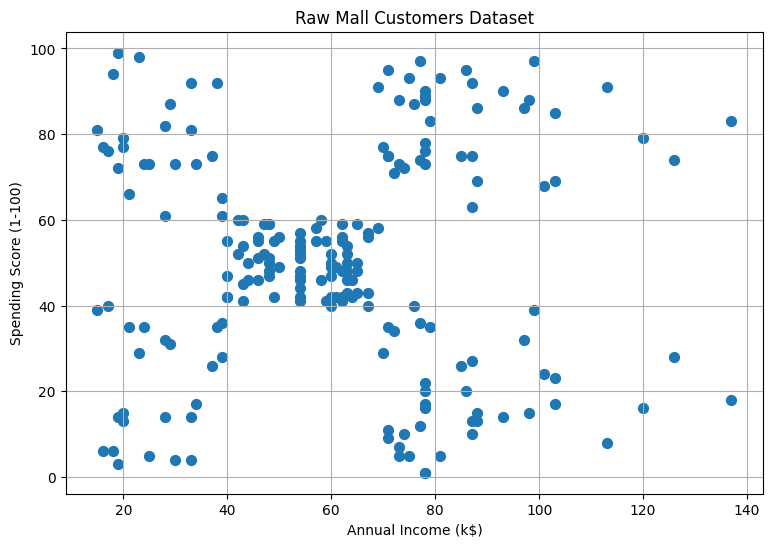

In [4]:
# Visualize raw dataset

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    s=50
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Raw Mall Customers Dataset')
plt.grid(True)
plt.show()


In [5]:
#Scaling the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Features scaled successfully!")

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(X_scaled.head())


Features scaled successfully!


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


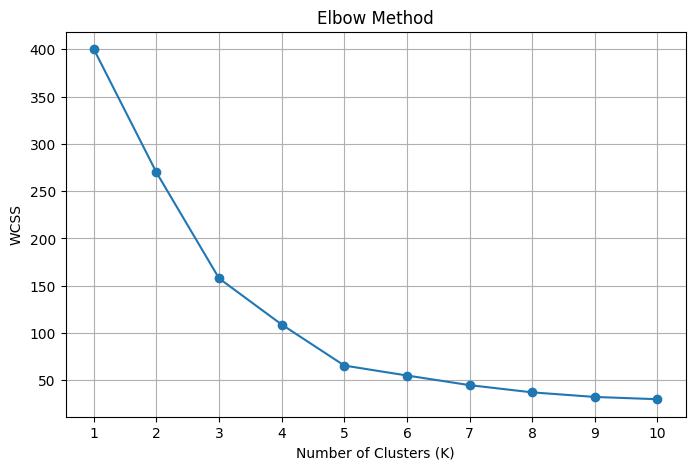

In [6]:
#elbow method
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [7]:
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means model fitted successfully!")
print("Number of clusters:", optimal_k)

print("\nCluster assignments:")
display(df.head())


K-Means model fitted successfully!
Number of clusters: 5

Cluster assignments:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


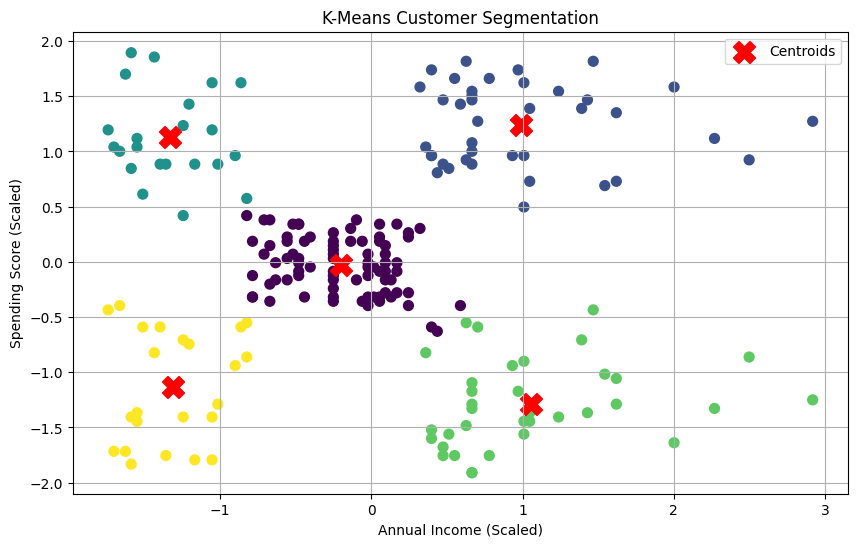

In [8]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled.iloc[:, 0],
    X_scaled.iloc[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    color='red',
    s=250,
    label='Centroids'
)

plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.title('K-Means Customer Segmentation')
plt.legend()
plt.grid(True)
plt.show()


In [9]:
# Number of customers in each cluster

print("Customers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

# Average feature values for each cluster

summary = df.groupby('Cluster').agg({
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'Age': 'mean',
    'CustomerID': 'count'
})

summary.rename(columns={
    'CustomerID': 'Number of Customers'
}, inplace=True)

print("\nCluster Summary:")
display(summary.round(2))


Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster Summary:


,Annual Income (k$),Spending Score (1-100),Age,Number of Customers
Cluster,,,,
0,55.30,49.52,42.72,81
1,86.54,82.13,32.69,39
2,25.73,79.36,25.27,22
3,88.20,17.11,41.11,35
4,26.30,20.91,45.22,23
